Libraries imported successfully!

Upload Kaggle data.csv file:


Saving data.csv to data.csv

Dataset loaded successfully!

First 5 rows:
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0

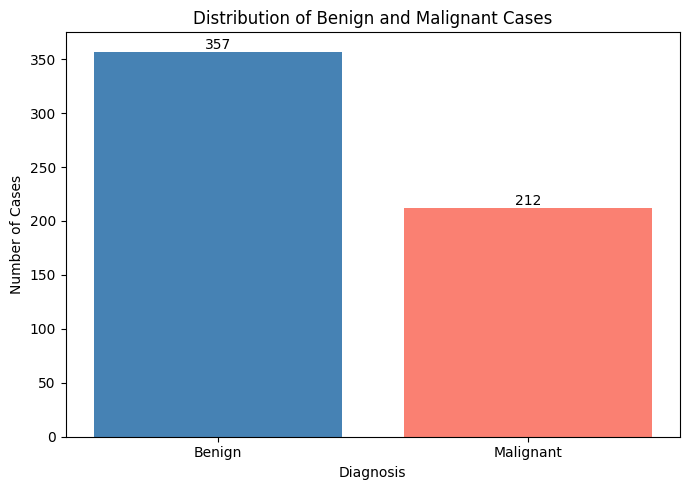


Input features: 30
Output: Benign (0) or Malignant (1)

Training data: 455
Testing data: 114

Decision Tree trained successfully!

Training Accuracy: 98.24 %
Testing Accuracy: 91.23 %

Classification Report:
              precision    recall  f1-score   support

      Benign       0.90      0.97      0.93        72
   Malignant       0.94      0.81      0.87        42

    accuracy                           0.91       114
   macro avg       0.92      0.89      0.90       114
weighted avg       0.91      0.91      0.91       114



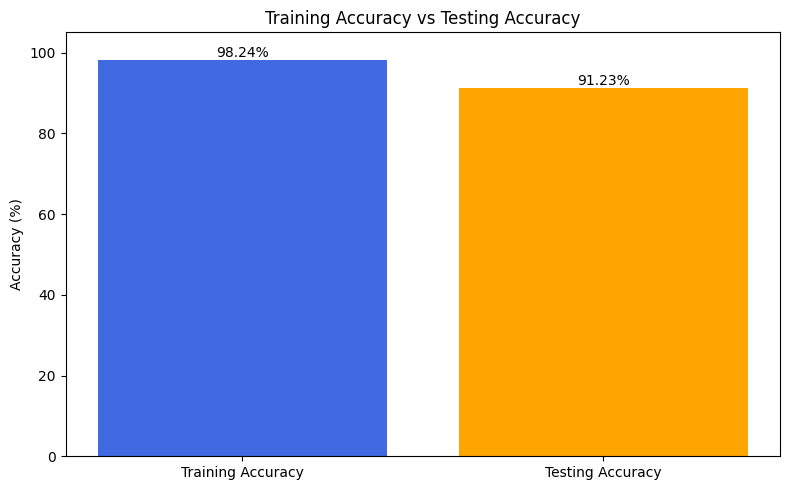

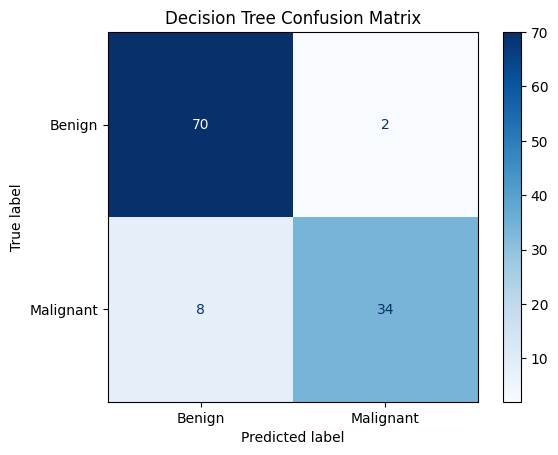


========== PAC ANALYSIS ==========
Confidence Level: 95.0 %
Number of Test Samples: 114
Observed Test Error: 0.0877
Error Margin (epsilon): 0.1272
Estimated True Error Interval: 0 to 0.2149
Upper Generalization Error Bound: 21.49 %
Lower Accuracy Bound: 78.51 %


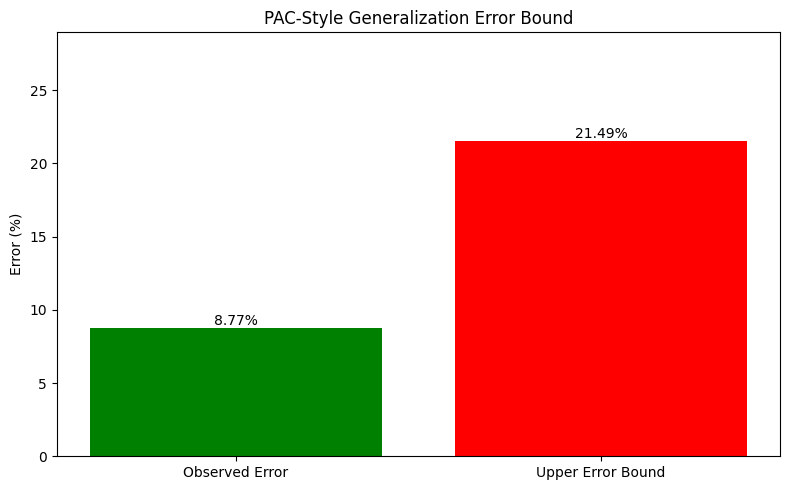


========== MANUAL PREDICTION ==========
Choose a test sample index from 0 to 113
Enter sample index: 3

Predicted Diagnosis: BENIGN
Actual Diagnosis: MALIGNANT


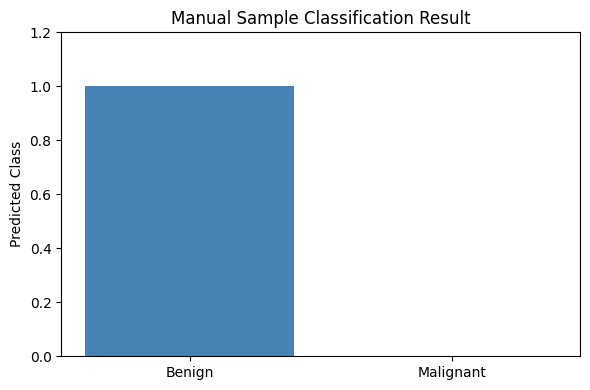


PAC Learning case study completed!


In [ ]:

# ==========================================================
# CASE STUDY 1: PAC LEARNING
# Dataset: Breast Cancer Wisconsin (Diagnostic) - Kaggle
# Algorithm: Decision Tree Classifier
# Concept: Probably Approximately Correct (PAC) Learning
# ==========================================================

# MODULE 1: IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

print("Libraries imported successfully!")


# MODULE 2: LOAD KAGGLE DATASET

print("\nUpload Kaggle data.csv file:")
uploaded = files.upload()

filename = next(iter(uploaded))
data = pd.read_csv(filename)

print("\nDataset loaded successfully!")
print("\nFirst 5 rows:")
print(data.head())

print("\nDataset shape:", data.shape)
print("\nDataset information:")
data.info()


# MODULE 3: DATA WRANGLING

print("\nBefore cleaning:", data.shape)

# Remove unwanted columns
data = data.drop(
    columns=["id", "Unnamed: 32"],
    errors="ignore"
)

# Remove missing and duplicate records
data = data.dropna()
data = data.drop_duplicates()

print("After cleaning:", data.shape)

print("\nMissing values:")
print(data.isnull().sum())

print("\nClass labels:")
print(data["diagnosis"].value_counts())


# GRAPH 1: CLASS DISTRIBUTION

counts = data["diagnosis"].value_counts()
counts = counts.reindex(["B", "M"], fill_value=0)

plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["Benign", "Malignant"],
    counts.values,
    color=["steelblue", "salmon"]
)

plt.title("Distribution of Benign and Malignant Cases")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Cases")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        str(int(bar.get_height())),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


# MODULE 4: SEPARATE INPUT AND OUTPUT

X = data.drop("diagnosis", axis=1)

# Encode target:
# 0 = Benign
# 1 = Malignant
y = data["diagnosis"].map({"B": 0, "M": 1})

print("\nInput features:", X.shape[1])
print("Output: Benign (0) or Malignant (1)")


# MODULE 5: TRAIN-TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining data:", len(X_train))
print("Testing data:", len(X_test))


# MODULE 6: MODEL TRAINING

# Decision Tree with limited complexity
model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

model.fit(X_train, y_train)

print("\nDecision Tree trained successfully!")


# MODULE 7: MODEL EVALUATION

train_prediction = model.predict(X_train)
test_prediction = model.predict(X_test)

train_accuracy = accuracy_score(
    y_train, train_prediction
) * 100

test_accuracy = accuracy_score(
    y_test, test_prediction
) * 100

print("\nTraining Accuracy:", round(train_accuracy, 2), "%")
print("Testing Accuracy:", round(test_accuracy, 2), "%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        test_prediction,
        target_names=["Benign", "Malignant"]
    )
)


# GRAPH 2: TRAINING VS TESTING ACCURACY

labels = ["Training Accuracy", "Testing Accuracy"]
values = [train_accuracy, test_accuracy]

plt.figure(figsize=(8, 5))
bars = plt.bar(
    labels,
    values,
    color=["royalblue", "orange"]
)

plt.title("Training Accuracy vs Testing Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 105)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{bar.get_height():.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


# GRAPH 3: CONFUSION MATRIX

cm = confusion_matrix(y_test, test_prediction)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Decision Tree Confusion Matrix")
plt.show()


# MODULE 8: PAC-STYLE GENERALIZATION BOUND

# Confidence bound using Hoeffding's inequality
# This applies to a fixed model evaluated on an
# independent test set.

delta = 0.05     # 95% confidence
n = len(X_test)

test_error = 1 - accuracy_score(
    y_test, test_prediction
)

epsilon = np.sqrt(
    np.log(2 / delta) / (2 * n)
)

lower_error = max(0, test_error - epsilon)
upper_error = min(1, test_error + epsilon)

print("\n========== PAC ANALYSIS ==========")

print("Confidence Level:", (1-delta)*100, "%")
print("Number of Test Samples:", n)
print("Observed Test Error:", round(test_error, 4))
print("Error Margin (epsilon):", round(epsilon, 4))

print(
    "Estimated True Error Interval:",
    round(lower_error, 4),
    "to",
    round(upper_error, 4)
)

print(
    "Upper Generalization Error Bound:",
    round(upper_error * 100, 2), "%"
)

print(
    "Lower Accuracy Bound:",
    round((1-upper_error)*100, 2), "%"
)


# GRAPH 4: PAC ERROR BOUND

plt.figure(figsize=(8, 5))

names = ["Observed Error", "Upper Error Bound"]
error_values = [test_error*100, upper_error*100]

bars = plt.bar(
    names,
    error_values,
    color=["green", "red"]
)

plt.title("PAC-Style Generalization Error Bound")
plt.ylabel("Error (%)")
plt.ylim(0, max(error_values)*1.3 + 1)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{bar.get_height():.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


# MODULE 9: MANUAL PREDICTION

print("\n========== MANUAL PREDICTION ==========")
print("Choose a test sample index from 0 to", len(X_test)-1)

index = int(input("Enter sample index: "))

if 0 <= index < len(X_test):

    sample = X_test.iloc[[index]]

    result = model.predict(sample)[0]
    actual = y_test.iloc[index]

    names = {0: "BENIGN", 1: "MALIGNANT"}

    print("\nPredicted Diagnosis:", names[result])
    print("Actual Diagnosis:", names[actual])

    # GRAPH 5: PREDICTION VISUALIZATION

    prediction_values = [
        int(result == 0),
        int(result == 1)
    ]

    plt.figure(figsize=(6, 4))

    plt.bar(
        ["Benign", "Malignant"],
        prediction_values,
        color=["steelblue", "salmon"]
    )

    plt.title("Manual Sample Classification Result")
    plt.ylabel("Predicted Class")
    plt.ylim(0, 1.2)

    plt.tight_layout()
    plt.show()

else:
    print("Invalid sample index!")

print("\nPAC Learning case study completed!")


In [ ]:

# 10.4 FEATURE SELECTION

print("Input Features:", X.shape[1])
print("Output Variable: Diagnosis")
print("Feature Names:", X.columns.tolist())
print("Benign = 0")
print("Malignant = 1")



Input Features: 30
Output Variable: Diagnosis
Feature Names: ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']
Benign = 0
Malignant = 1


Saving data.csv to data (1).csv
Dataset Loaded Successfully!
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

 

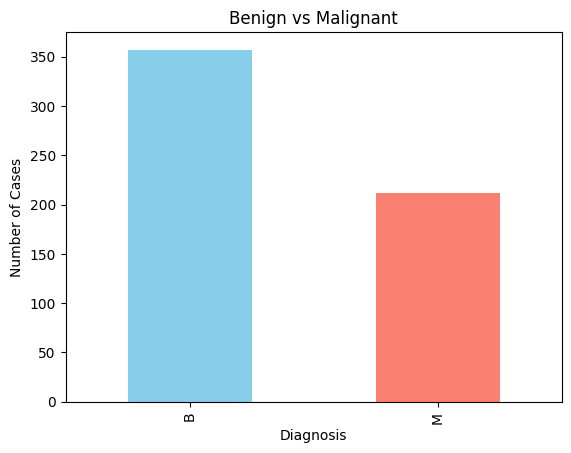


Input Features: 30
Output: Benign (0) or Malignant (1)
Training Data: 455
Testing Data: 114

Best CV Accuracy: 94.29 %
Selected Tree Depth: 5


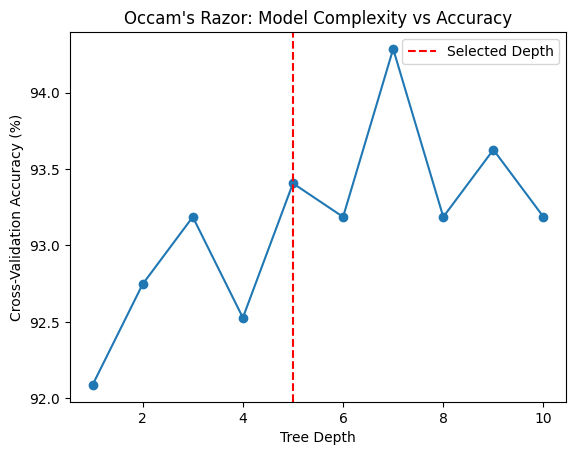


Occam's Razor Model Trained Successfully!
Selected Tree Depth: 5
Number of Tree Nodes: 31
Training Accuracy: 98.68 %
Testing Accuracy: 92.11 %


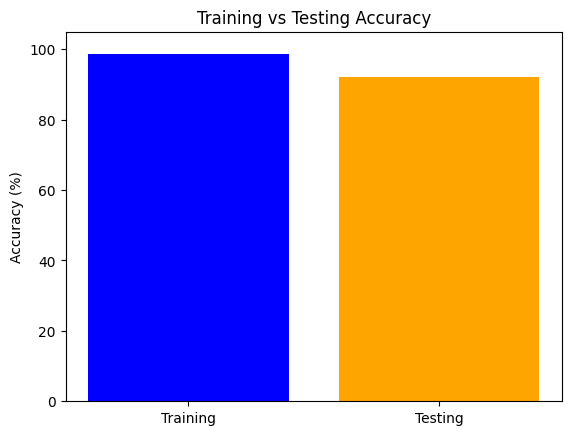

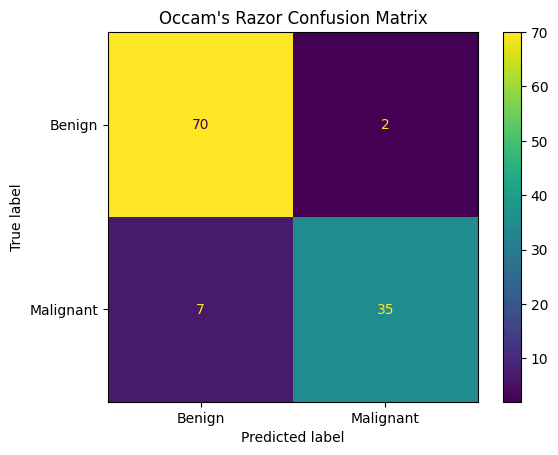


Simple Tree Nodes: 31
Complex Tree Nodes: 47
Simple Tree Accuracy: 92.11 %
Complex Tree Accuracy: 92.98 %


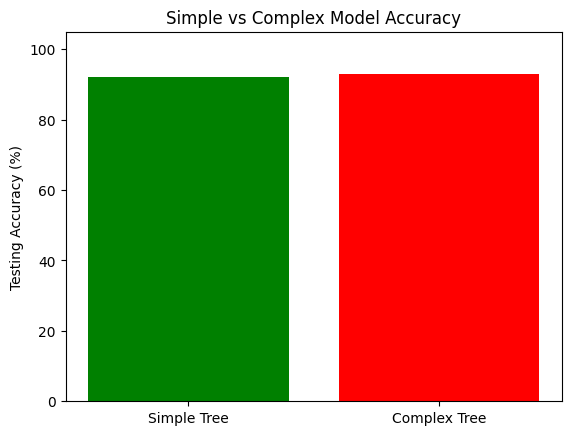

Enter Test Sample Index (0 to 113): 4
Predicted Result: Benign
Actual Result: Benign


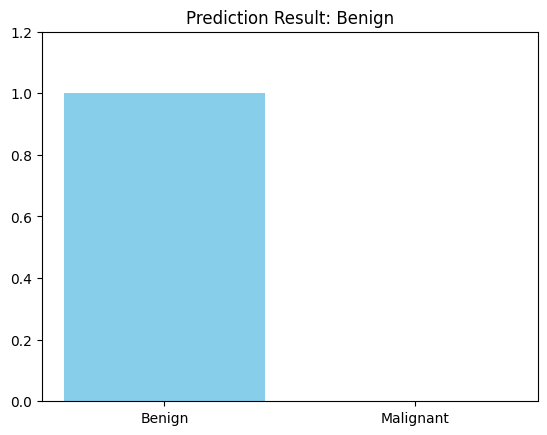

In [ ]:

# OCCAM'S RAZOR - BREAST CANCER PREDICTION

# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

# 2. Load Dataset
uploaded = files.upload()
data = pd.read_csv(next(iter(uploaded)))

print("Dataset Loaded Successfully!")
print(data.head())
print("Dataset Shape:", data.shape)

# 3. Data Cleaning
print("\nBefore Cleaning:", data.shape)
data = data.drop(columns=["id", "Unnamed: 32"], errors="ignore")
data = data.dropna().drop_duplicates()
print("After Cleaning:", data.shape)
print("Missing Values:", data.isnull().sum().sum())

# 4. Class Distribution
data["diagnosis"].value_counts().reindex(["B", "M"]).plot(
    kind="bar", color=["skyblue", "salmon"]
)
plt.title("Benign vs Malignant")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Cases")
plt.show()

# 5. Input and Output
X = data.drop("diagnosis", axis=1)
y = data["diagnosis"].map({"B": 0, "M": 1})

print("\nInput Features:", X.shape[1])
print("Output: Benign (0) or Malignant (1)")

# 6. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training Data:", len(X_train))
print("Testing Data:", len(X_test))

# 7. Compare Simple and Complex Models
depths = range(1, 11)
cv_scores = []

for depth in depths:
    tree = DecisionTreeClassifier(
        max_depth=depth, random_state=42
    )
    scores = cross_val_score(
        tree, X_train, y_train, cv=5
    )
    cv_scores.append(scores.mean())

# Occam's Razor: choose the smallest tree whose
# CV accuracy is within 1% of the best CV accuracy
best_score = max(cv_scores)
selected_depth = next(
    d for d, score in zip(depths, cv_scores)
    if score >= best_score - 0.01
)

print("\nBest CV Accuracy:", round(best_score * 100, 2), "%")
print("Selected Tree Depth:", selected_depth)

# 8. Model Complexity Graph
plt.plot(list(depths), np.array(cv_scores)*100, marker="o")
plt.axvline(selected_depth, color="red",
            linestyle="--", label="Selected Depth")
plt.title("Occam's Razor: Model Complexity vs Accuracy")
plt.xlabel("Tree Depth")
plt.ylabel("Cross-Validation Accuracy (%)")
plt.legend()
plt.show()

# 9. Train Selected Model
model = DecisionTreeClassifier(
    max_depth=selected_depth, random_state=42
)
model.fit(X_train, y_train)

print("\nOccam's Razor Model Trained Successfully!")
print("Selected Tree Depth:", selected_depth)
print("Number of Tree Nodes:", model.tree_.node_count)

# 10. Model Accuracy
train_acc = accuracy_score(
    y_train, model.predict(X_train)
) * 100
test_acc = accuracy_score(
    y_test, model.predict(X_test)
) * 100

print("Training Accuracy:", round(train_acc, 2), "%")
print("Testing Accuracy:", round(test_acc, 2), "%")

# 11. Accuracy Graph
plt.bar(["Training", "Testing"], [train_acc, test_acc],
        color=["blue", "orange"])
plt.title("Training vs Testing Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 105)
plt.show()

# 12. Confusion Matrix
ConfusionMatrixDisplay.from_estimator(
    model, X_test, y_test,
    display_labels=["Benign", "Malignant"]
)
plt.title("Occam's Razor Confusion Matrix")
plt.show()

# 13. Compare Simple vs Complex Tree
complex_model = DecisionTreeClassifier(random_state=42)
complex_model.fit(X_train, y_train)

simple_accuracy = test_acc
complex_accuracy = accuracy_score(
    y_test, complex_model.predict(X_test)
) * 100

print("\nSimple Tree Nodes:", model.tree_.node_count)
print("Complex Tree Nodes:", complex_model.tree_.node_count)
print("Simple Tree Accuracy:", round(simple_accuracy, 2), "%")
print("Complex Tree Accuracy:", round(complex_accuracy, 2), "%")

plt.bar(["Simple Tree", "Complex Tree"],
        [simple_accuracy, complex_accuracy],
        color=["green", "red"])
plt.title("Simple vs Complex Model Accuracy")
plt.ylabel("Testing Accuracy (%)")
plt.ylim(0, 105)
plt.show()

# 14. Manual Prediction
i = int(input("Enter Test Sample Index (0 to 113): "))

if 0 <= i < len(X_test):
    prediction = model.predict(X_test.iloc[[i]])[0]
    result = "Malignant" if prediction == 1 else "Benign"

    print("Predicted Result:", result)
    print("Actual Result:",
          "Malignant" if y_test.iloc[i] == 1 else "Benign")

    plt.bar(["Benign", "Malignant"],
            [int(prediction == 0), int(prediction == 1)],
            color=["skyblue", "salmon"])
    plt.title("Prediction Result: " + result)
    plt.ylim(0, 1.2)
    plt.show()
else:
    print("Invalid Index")


Saving data.csv to data (2).csv
Dataset Loaded Successfully!
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

 

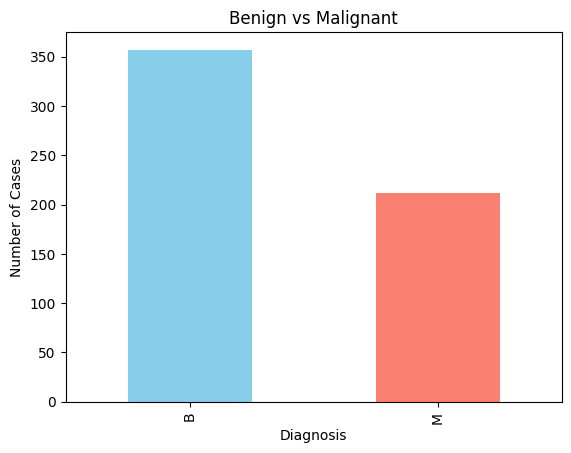


Input Features: 30
Output: Benign (0) or Malignant (1)
Training Data: 455
Testing Data: 114
Feature Scaling Completed!

L1 Model Trained Successfully!
L2 Model Trained Successfully!

L1 Training Accuracy: 98.68 %
L1 Testing Accuracy: 97.37 %
L2 Training Accuracy: 98.9 %
L2 Testing Accuracy: 97.37 %


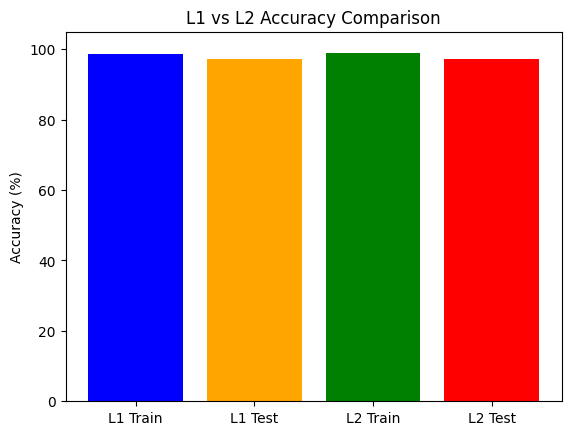

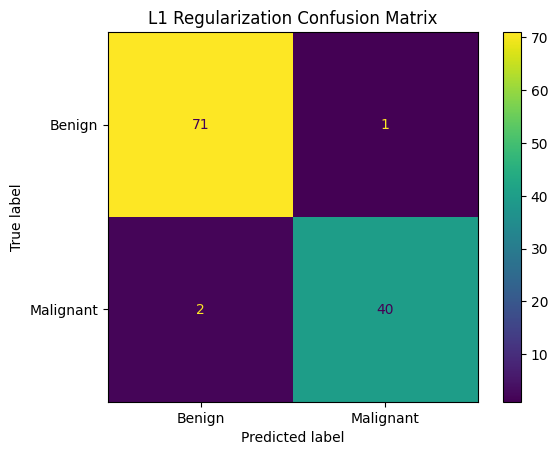

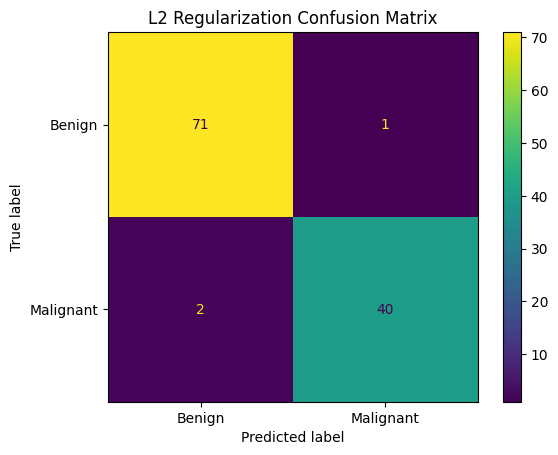


L1 Non-Zero Features: 14
L2 Non-Zero Features: 30


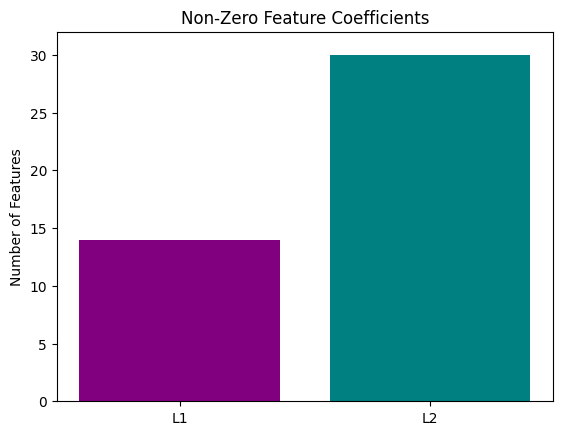

Enter Test Sample Index (0 to 113): 5
L1 Prediction: Benign
L2 Prediction: Benign
Actual Result: Benign


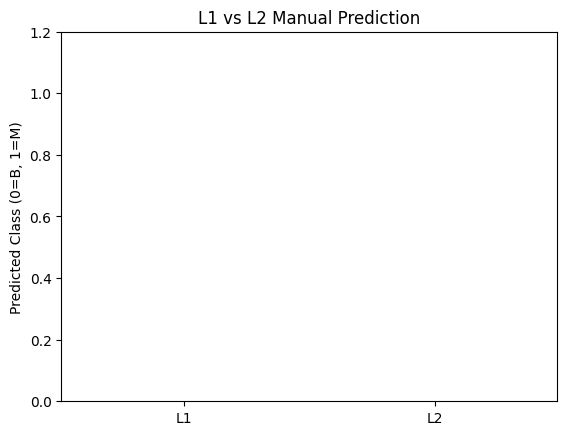

In [ ]:

# L1 AND L2 REGULARIZATION - BREAST CANCER PREDICTION

# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

# 2. Load Dataset
uploaded = files.upload()
data = pd.read_csv(next(iter(uploaded)))

print("Dataset Loaded Successfully!")
print(data.head())
print("Dataset Shape:", data.shape)

# 3. Data Cleaning
print("\nBefore Cleaning:", data.shape)
data = data.drop(columns=["id", "Unnamed: 32"], errors="ignore")
data = data.dropna().drop_duplicates()
print("After Cleaning:", data.shape)
print("Missing Values:", data.isnull().sum().sum())

# 4. Dataset Distribution
data["diagnosis"].value_counts().reindex(["B", "M"]).plot(
    kind="bar", color=["skyblue", "salmon"]
)
plt.title("Benign vs Malignant")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Cases")
plt.show()

# 5. Input and Output
X = data.drop("diagnosis", axis=1)
y = data["diagnosis"].map({"B": 0, "M": 1})

print("\nInput Features:", X.shape[1])
print("Output: Benign (0) or Malignant (1)")

# 6. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training Data:", len(X_train))
print("Testing Data:", len(X_test))

# 7. Feature Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print("Feature Scaling Completed!")

# 8. Train L1 Model
l1 = LogisticRegression(
    penalty="l1", solver="liblinear",
    C=1.0, max_iter=2000, random_state=42
)
l1.fit(X_train, y_train)
print("\nL1 Model Trained Successfully!")

# 9. Train L2 Model
l2 = LogisticRegression(
    penalty="l2", solver="liblinear",
    C=1.0, max_iter=2000, random_state=42
)
l2.fit(X_train, y_train)
print("L2 Model Trained Successfully!")

# 10. Model Accuracy
l1_train = accuracy_score(y_train, l1.predict(X_train))*100
l1_test = accuracy_score(y_test, l1.predict(X_test))*100

l2_train = accuracy_score(y_train, l2.predict(X_train))*100
l2_test = accuracy_score(y_test, l2.predict(X_test))*100

print("\nL1 Training Accuracy:", round(l1_train, 2), "%")
print("L1 Testing Accuracy:", round(l1_test, 2), "%")
print("L2 Training Accuracy:", round(l2_train, 2), "%")
print("L2 Testing Accuracy:", round(l2_test, 2), "%")

# 11. Accuracy Comparison Graph
labels = ["L1 Train", "L1 Test", "L2 Train", "L2 Test"]
values = [l1_train, l1_test, l2_train, l2_test]

plt.bar(labels, values,
        color=["blue", "orange", "green", "red"])
plt.title("L1 vs L2 Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 105)
plt.show()

# 12. Confusion Matrices
ConfusionMatrixDisplay.from_estimator(
    l1, X_test, y_test,
    display_labels=["Benign", "Malignant"]
)
plt.title("L1 Regularization Confusion Matrix")
plt.show()

ConfusionMatrixDisplay.from_estimator(
    l2, X_test, y_test,
    display_labels=["Benign", "Malignant"]
)
plt.title("L2 Regularization Confusion Matrix")
plt.show()

# 13. Feature Selection and Coefficients
l1_features = np.sum(np.abs(l1.coef_) > 1e-6)
l2_features = np.sum(np.abs(l2.coef_) > 1e-6)

print("\nL1 Non-Zero Features:", l1_features)
print("L2 Non-Zero Features:", l2_features)

plt.bar(["L1", "L2"], [l1_features, l2_features],
        color=["purple", "teal"])
plt.title("Non-Zero Feature Coefficients")
plt.ylabel("Number of Features")
plt.ylim(0, 32)
plt.show()

# 14. Manual Prediction
i = int(input("Enter Test Sample Index (0 to 113): "))

if 0 <= i < len(X_test):
    p1 = l1.predict(X_test[i:i+1])[0]
    p2 = l2.predict(X_test[i:i+1])[0]

    names = {0: "Benign", 1: "Malignant"}

    print("L1 Prediction:", names[p1])
    print("L2 Prediction:", names[p2])
    print("Actual Result:", names[y_test.iloc[i]])

    plt.bar(["L1", "L2"], [p1, p2],
            color=["purple", "teal"])
    plt.title("L1 vs L2 Manual Prediction")
    plt.ylabel("Predicted Class (0=B, 1=M)")
    plt.ylim(0, 1.2)
    plt.show()
else:
    print("Invalid Index")
